# Clean Data and EDA

In [1]:
import pandas as pd
import numpy as np


In [2]:
df1_animation = pd.read_csv("data/Animation_Movies.csv")
df2_action = pd.read_csv("data/action.csv")
df3_nvda = pd.read_csv("data/NVDA.csv")

### Dataframe 1: 

In [3]:
df1_animation.head()

,id,title,vote_average,vote_count,status,release_date,revenue,runtime,adult,backdrop_path,...,original_language,original_title,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages
0,150540,Inside Out,7.922,19463,Released,2015-06-09,857611174,95,False,/j29ekbcLpBvxnGk6LjdTc2EI5SA.jpg,...,en,Inside Out,"Growing up can be a bumpy road, and it's no ex...",107.292,/2H1TmgdfNtsKlU9jKdeNyYL5y8T.jpg,Meet the little voices inside your head.,"Animation, Family, Adventure, Drama, Comedy","Pixar, Walt Disney Pictures",United States of America,English
1,14160,Up,7.949,18857,Released,2009-05-28,735099082,96,False,/hGGC9gKo7CFE3fW07RA587e5kol.jpg,...,en,Up,Carl Fredricksen spent his entire life dreamin...,90.968,/vpbaStTMt8qqXaEgnOR2EE4DNJk.jpg,The greatest adventure is just getting back home.,"Animation, Comedy, Family, Adventure",Pixar,United States of America,English
2,12,Finding Nemo,7.824,18061,Released,2003-05-30,940335536,100,False,/h3uqFk7sZRJvLZDdLiFB9qwbL07.jpg,...,en,Finding Nemo,"Nemo, an adventurous young clownfish, is unexp...",55.456,/ggQ6o8X5984OCh3kZi2UIJQJY5y.jpg,There are 3.7 trillion fish in the ocean. They...,"Animation, Family",Pixar,United States of America,English
3,354912,Coco,8.222,17742,Released,2017-10-27,800526015,105,False,/askg3SMvhqEl4OL52YuvdtY40Yb.jpg,...,en,Coco,Despite his family’s baffling generations-old ...,166.578,/gGEsBPAijhVUFoiNpgZXqRVWJt2.jpg,The celebration of a lifetime,"Family, Animation, Fantasy, Music, Comedy, Adv...","Pixar, Walt Disney Pictures",United States of America,"English, Spanish"
4,10681,WALL·E,8.078,17446,Released,2008-06-22,521311860,98,False,/fK5ssgvtI43z19FoWigdlqgpLRE.jpg,...,en,WALL·E,What if mankind had to leave Earth and somebod...,58.517,/hbhFnRzzg6ZDmm8YAmxBnQpQIPh.jpg,After 700 years of doing what he was built for...,"Animation, Family, Science Fiction","Pixar, Walt Disney Pictures",United States of America,English


In [4]:
df1_animation.info()

<class 'pandas.DataFrame'>
RangeIndex: 51945 entries, 0 to 51944
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    51945 non-null  int64  
 1   title                 51944 non-null  str    
 2   vote_average          51945 non-null  float64
 3   vote_count            51945 non-null  int64  
 4   status                51945 non-null  str    
 5   release_date          49808 non-null  str    
 6   revenue               51945 non-null  int64  
 7   runtime               51945 non-null  int64  
 8   adult                 51945 non-null  bool   
 9   backdrop_path         15835 non-null  str    
 10  budget                51945 non-null  int64  
 11  homepage              8253 non-null   str    
 12  imdb_id               29552 non-null  str    
 13  original_language     51945 non-null  str    
 14  original_title        51944 non-null  str    
 15  overview              45866 no

#### Cleaning Dataframe 1

In [5]:
df1_animation.isnull().sum()

id                          0
title                       1
vote_average                0
vote_count                  0
status                      0
release_date             2137
revenue                     0
runtime                     0
adult                       0
backdrop_path           36110
budget                      0
homepage                43692
imdb_id                 22393
original_language           0
original_title              1
overview                 6079
popularity                  0
poster_path             14011
tagline                 47267
genres                      0
production_companies    22547
production_countries    12245
spoken_languages        18127
dtype: int64

In [6]:
df1_animation.duplicated().sum()

np.int64(0)

In [7]:
df1_animation[df1_animation.duplicated()]

,id,title,vote_average,vote_count,status,release_date,revenue,runtime,adult,backdrop_path,...,original_language,original_title,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages


In [8]:
missing_percent = df1_animation.isnull().mean() * 100

missing_percent.sort_values(ascending=False)

tagline                 90.994321
homepage                84.112042
backdrop_path           69.515834
production_companies    43.405525
imdb_id                 43.109058
spoken_languages        34.896525
poster_path             26.972760
production_countries    23.573010
overview                11.702763
release_date             4.113967
original_title           0.001925
title                    0.001925
id                       0.000000
vote_count               0.000000
vote_average             0.000000
revenue                  0.000000
status                   0.000000
adult                    0.000000
budget                   0.000000
original_language        0.000000
runtime                  0.000000
popularity               0.000000
genres                   0.000000
dtype: float64

In [ ]:
columns_to_drop = [
    "tagline",
    "homepage",
    "backdrop_path",
    "poster_path"
]

df1_animation = df1_animation.drop(columns=columns_to_drop)


In [ ]:
df1_animation.shape

(51945, 19)

In [ ]:
df1_animation["id"].duplicated().sum()

np.int64(0)

In [ ]:
df1_animation["release_date"] = pd.to_datetime(
    df1_animation["release_date"],
    errors="coerce"
)

In [ ]:
df1_animation["release_date"].head()

0   2015-06-09
1   2009-05-28
2   2003-05-30
3   2017-10-27
4   2008-06-22
Name: release_date, dtype: datetime64[us]

In [ ]:
df1_animation["release_date"].isnull().sum()

np.int64(2137)

In [ ]:
df1_animation[[
    "vote_average",
    "vote_count",
    "revenue",
    "runtime",
    "budget",
    "popularity"
]].describe()

,vote_average,vote_count,revenue,runtime,budget,popularity
count,51945.000000,51945.000000,5.194500e+04,51945.000000,5.194500e+04,51945.000000
mean,2.597083,40.395380,1.863464e+06,20.901415,5.759513e+05,1.886233
std,3.318748,482.705948,3.049824e+07,39.016002,7.606628e+06,9.700913
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000
25%,0.000000,0.000000,0.000000e+00,3.000000,0.000000e+00,0.600000
50%,0.000000,0.000000,0.000000e+00,7.000000,0.000000e+00,0.600000
75%,6.000000,2.000000,0.000000e+00,19.000000,0.000000e+00,0.882000
max,10.000000,19463.000000,1.450027e+09,3720.000000,2.600000e+08,1008.942000


In [ ]:
columns = [
    "vote_average",
    "vote_count",
    "revenue",
    "runtime",
    "budget",
    "popularity"
]

(df1_animation[columns] == 0).sum()

vote_average    30789
vote_count      30779
revenue         50845
runtime          6301
budget          50342
popularity        963
dtype: int64

In [17]:
df1_animation["budget"] = df1_animation["budget"].replace(0, np.nan)
df1_animation["revenue"] = df1_animation["revenue"].replace(0, np.nan)
df1_animation["runtime"] = df1_animation["runtime"].replace(0, np.nan)

df1_animation[["budget", "revenue", "runtime"]].isnull().sum()

budget     50342
revenue    50845
runtime     6301
dtype: int64

In [18]:
df1_animation[
    (df1_animation["vote_average"] == 0) &
    (df1_animation["vote_count"] > 0)
][["title", "vote_average", "vote_count"]]

,title,vote_average,vote_count
13117,Dissolutions,0.0,2
13295,Little Thing,0.0,2
14834,Fly,0.0,1
14968,Rising Waters In Underwood Springs,0.0,1
15050,A Wiz named WuKong,0.0,1
15474,Augur,0.0,1
15499,Highlights Watch & Learn!: Holiday Fun!,0.0,1
15590,Tomorrow My Love,0.0,1
15691,Summer with Kuro,0.0,1
15864,Siva II,0.0,1


In [ ]:
df1_animation[
    (df1_animation["vote_count"] == 0) &
    (df1_animation["vote_average"] != 0)
][["title", "vote_average", "vote_count"]]

,title,vote_average,vote_count
21554,Looking For Santa,6.0,0
24205,Passenger,7.0,0
27253,Hecate,3.0,0
28392,Yampa,10.0,0
31599,Being Pretty,5.0,0
32101,Three Jolly Fellows,9.0,0
37475,The Goofy Adventure Story,6.0,0
38466,After Us,6.0,0
38560,Lost Senses,7.0,0
38944,Recently in the Woods,3.0,0


In [ ]:
(df1_animation["vote_count"] > 0).sum()

np.int64(21166)

In [ ]:
df1_animation.loc[
    df1_animation["vote_count"] > 0,
    "vote_count"
].describe()

count    21166.000000
mean        99.137201
std        752.347400
min          1.000000
25%          1.000000
50%          3.000000
75%         13.000000
max      19463.000000
Name: vote_count, dtype: float64

In [22]:
df1_animation[
    ["title", "runtime", "release_date"]
].sort_values(
    by="runtime",
    ascending=False
).head(20)

,title,runtime,release_date
20296,Giant 600 Cartoon Collection,3720.0,2008-07-22
38214,200 Family Cartoons Collection Vol. 1,1335.0,NaT
43438,150 Cartoon Classics,1035.0,2006-02-07
16130,The New Adventures of Winnie the Pooh,999.0,1988-01-17
23201,The Scooby-Doo Show,960.0,1976-09-11
23253,The New Scooby-Doo Movies,960.0,1972-09-09
32340,Metalocalypse (2006-2012),740.0,NaT
26837,Legend of the Yôkai: The Cat-Eyed Boy,720.0,1976-04-01
31440,Cocorico,676.0,2013-01-01
14079,Miss Spider's Sunny Patch Kids,666.0,2003-03-31


In [23]:
df1_animation["runtime"].describe()

count    45644.000000
mean        23.786785
std         40.789203
min          1.000000
25%          5.000000
50%          8.000000
75%         25.000000
max       3720.000000
Name: runtime, dtype: float64

In [ ]:
df1_animation[["budget", "revenue"]].describe()

,budget,revenue
count,1.603000e+03,1.100000e+03
mean,1.866362e+07,8.799786e+07
std,3.922133e+07,1.907261e+08
min,1.000000e+00,1.000000e+00
25%,2.000000e+03,5.147698e+05
50%,2.600000e+05,8.677055e+06
75%,1.338466e+07,6.423234e+07
max,2.600000e+08,1.450027e+09


In [ ]:
df1_animation[["budget", "revenue"]].notna().sum()

budget     1603
revenue    1100
dtype: int64

In [ ]:
(df1_animation["budget"].notna() &
 df1_animation["revenue"].notna()).sum()

np.int64(647)

In [27]:
df1_animation[
    ["title", "budget", "revenue", "release_date"]
].dropna(subset=["budget"]).sort_values(
    "budget"
).head(20)

,title,budget,revenue,release_date
47178,Thiruvalar Panchankam,1.0,1.0,2020-12-11
6194,The Ugly Duckling,1.0,NaN,2010-09-16
21752,Bizarre Webcomic's Max Aventura,1.0,NaN,2021-02-10
19558,Sentimento,1.0,NaN,2012-12-26
39597,10+2: The Great Secret,1.0,246.0,2001-08-17
27844,A Comic Zoom,1.0,1.0,1985-05-01
24671,From Zero to One,1.0,NaN,2021-09-09
19967,The Rise of Miss Power,1.0,1.0,NaT
37367,The Van,1.0,1.0,2016-04-17
28401,Life Of A Sun Warrior,1.0,1.0,2023-07-04


In [28]:
df1_animation[
    ["title", "budget", "revenue", "release_date"]
].dropna(subset=["revenue"]).sort_values(
    "revenue"
).head(20)

,title,budget,revenue,release_date
30329,Steamboat Willie (Brock’s Dub),NaN,1.0,2024-01-04
32789,Good Morning,1.0,1.0,2007-09-11
21580,Fart: The Movie Pilot,NaN,1.0,2022-02-03
27844,A Comic Zoom,1.0,1.0,1985-05-01
19967,The Rise of Miss Power,1.0,1.0,NaT
15033,mania,1.0,1.0,2020-10-23
13688,H40,10.0,1.0,2023-03-17
18174,Maturation,1.0,1.0,NaT
16963,bart sra,1.0,1.0,2020-06-08
47178,Thiruvalar Panchankam,1.0,1.0,2020-12-11


In [29]:
df1_animation[
    ["title", "budget", "revenue", "release_date"]
].sort_values(
    "budget",
    ascending=False
).head(20)

,title,budget,revenue,release_date
29,Tangled,260000000.0,5.924617e+08,2010-11-24
195,Elemental,200000000.0,4.867980e+08,2023-06-14
23,Incredibles 2,200000000.0,1.242805e+09,2018-06-14
35,Monsters University,200000000.0,7.435596e+08,2013-06-19
127,A Christmas Carol,200000000.0,3.252866e+08,2009-11-04
17,Toy Story 3,200000000.0,1.066970e+09,2010-06-16
26,Finding Dory,200000000.0,1.028571e+09,2016-06-16
167,Lightyear,200000000.0,2.264254e+08,2022-06-15
32258,Wish,200000000.0,NaN,2023-11-22
86,Onward,200000000.0,1.419400e+08,2020-02-29


In [30]:
df1_animation[
    ["title", "budget", "revenue", "release_date"]
].sort_values(
    "revenue",
    ascending=False
).head(20)

,title,budget,revenue,release_date
40,Frozen II,150000000.0,1.450027e+09,2019-11-20
67,The Super Mario Bros. Movie,100000000.0,1.355725e+09,2023-04-05
11,Frozen,150000000.0,1.274219e+09,2013-11-20
23,Incredibles 2,200000000.0,1.242805e+09,2018-06-14
34,Minions,74000000.0,1.156731e+09,2015-06-17
38,Toy Story 4,175000000.0,1.073395e+09,2019-06-19
17,Toy Story 3,200000000.0,1.066970e+09,2010-06-16
70,Despicable Me 3,80000000.0,1.031553e+09,2017-06-15
26,Finding Dory,200000000.0,1.028571e+09,2016-06-16
12,Zootopia,150000000.0,1.023784e+09,2016-02-11


#### Dataframe 1: Categorical Columns 

In [ ]:
df1_animation["status"].value_counts()

status
Released           51134
In Production        381
Planned              305
Post Production       97
Canceled              17
Rumored               11
Name: count, dtype: int64

In [ ]:
df1_animation["original_language"].value_counts().head(20)

original_language
en    28584
ja     5330
fr     2998
ru     2871
es     1472
de     1266
xx     1011
zh     1000
pt      947
pl      759
cs      616
ko      466
it      457
nl      428
uk      410
sv      375
hu      293
da      240
et      222
lv      191
Name: count, dtype: int64

In [33]:
df1_animation["genres"].value_counts().head(20)

genres
Animation                       28393
Animation, Comedy                2514
Animation, Family                2247
Family, Animation                 831
Documentary, Animation            793
Animation, Drama                  773
Comedy, Animation                 772
Animation, Documentary            733
Animation, Fantasy                686
Animation, Music                  637
Animation, Comedy, Family         633
Animation, Science Fiction        407
Animation, Horror                 387
Animation, Adventure              280
Drama, Animation                  264
Animation, Family, Comedy         243
Animation, Family, Fantasy        196
Animation, Adventure, Family      193
Music, Animation                  186
Fantasy, Animation                183
Name: count, dtype: int64

In [34]:
df1_animation["genres_clean"] = df1_animation["genres"].apply(
    lambda x: ", ".join(sorted(x.split(", ")))
)

In [35]:
df1_animation["genres_clean"].value_counts().head(20)

genres_clean
Animation                                28393
Animation, Comedy                         3286
Animation, Family                         3078
Animation, Documentary                    1526
Animation, Comedy, Family                 1110
Animation, Drama                          1037
Animation, Fantasy                         869
Animation, Music                           823
Animation, Science Fiction                 573
Animation, Horror                          529
Adventure, Animation, Family               498
Adventure, Animation                       381
Animation, Family, Fantasy                 362
Action, Animation, Science Fiction         292
Adventure, Animation, Comedy, Family       274
Action, Animation                          266
Adventure, Animation, Fantasy              230
Adventure, Animation, Comedy               214
Animation, Comedy, Fantasy                 197
Adventure, Animation, Family, Fantasy      187
Name: count, dtype: int64

In [36]:
df1_animation.info()

<class 'pandas.DataFrame'>
RangeIndex: 51945 entries, 0 to 51944
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   id                    51945 non-null  int64         
 1   title                 51944 non-null  str           
 2   vote_average          51945 non-null  float64       
 3   vote_count            51945 non-null  int64         
 4   status                51945 non-null  str           
 5   release_date          49808 non-null  datetime64[us]
 6   revenue               1100 non-null   float64       
 7   runtime               45644 non-null  float64       
 8   adult                 51945 non-null  bool          
 9   budget                1603 non-null   float64       
 10  imdb_id               29552 non-null  str           
 11  original_language     51945 non-null  str           
 12  original_title        51944 non-null  str           
 13  overview              45866

In [37]:
df1_animation.isnull().sum().sort_values(ascending=False)

revenue                 50845
budget                  50342
production_companies    22547
imdb_id                 22393
spoken_languages        18127
production_countries    12245
runtime                  6301
overview                 6079
release_date             2137
original_title              1
title                       1
id                          0
vote_count                  0
vote_average                0
status                      0
adult                       0
original_language           0
popularity                  0
genres                      0
genres_clean                0
dtype: int64

In [ ]:
df1_animation.shape

(51945, 20)

In [ ]:
df1_animation.columns

Index(['id', 'title', 'vote_average', 'vote_count', 'status', 'release_date',
       'revenue', 'runtime', 'adult', 'budget', 'imdb_id', 'original_language',
       'original_title', 'overview', 'popularity', 'genres',
       'production_companies', 'production_countries', 'spoken_languages',
       'genres_clean'],
      dtype='str')

In [40]:
df1_animation.to_csv(
    "data/Animation_Movies_clean.csv",
    index=False
)

In [ ]:
import os

os.path.exists("data/Animation_Movies_clean.csv")

True

## Dataframe 2: 

In [42]:
df2_action.head()

,movie_id,movie_name,year,certificate,runtime,genre,rating,description,director,director_id,star,star_id,votes,gross(in $)
0,tt9114286,Black Panther: Wakanda Forever,2022,PG-13,161 min,"Action, Adventure, Drama",6.9,The people of Wakanda fight to protect their h...,Ryan Coogler,/name/nm3363032/,"Letitia Wright, \nLupita Nyong'o, \nDanai Guri...","/name/nm4004793/,/name/nm2143282/,/name/nm1775...",204835.0,NaN
1,tt1630029,Avatar: The Way of Water,2022,PG-13,192 min,"Action, Adventure, Fantasy",7.8,Jake Sully lives with his newfound family form...,James Cameron,/name/nm0000116/,"Sam Worthington, \nZoe Saldana, \nSigourney We...","/name/nm0941777/,/name/nm0757855/,/name/nm0000...",295119.0,NaN
2,tt5884796,Plane,2023,R,107 min,"Action, Thriller",6.5,A pilot finds himself caught in a war zone aft...,Jean-François Richet,/name/nm0724938/,"Gerard Butler, \nMike Colter, \nTony Goldwyn, ...","/name/nm0124930/,/name/nm1591496/,/name/nm0001...",26220.0,NaN
3,tt6710474,Everything Everywhere All at Once,2022,R,139 min,"Action, Adventure, Comedy",8.0,A middle-aged Chinese immigrant is swept up in...,"Dan Kwan, \nDaniel Scheinert",/name/nm3453283/,"Michelle Yeoh, \nStephanie Hsu, \nJamie Lee Cu...","/name/nm3215397/,/name/nm0000706/,/name/nm3513...",327858.0,NaN
4,tt5433140,Fast X,2023,NaN,NaN,"Action, Crime, Mystery",NaN,Dom Toretto and his family are targeted by the...,Louis Leterrier,/name/nm0504642/,"Vin Diesel, \nJordana Brewster, \nTyrese Gibso...","/name/nm0004874/,/name/nm0108287/,/name/nm0879...",NaN,NaN


In [43]:
df2_action.info()

<class 'pandas.DataFrame'>
RangeIndex: 52452 entries, 0 to 52451
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   movie_id     52452 non-null  str    
 1   movie_name   52451 non-null  str    
 2   year         44193 non-null  str    
 3   certificate  13668 non-null  str    
 4   runtime      32530 non-null  str    
 5   genre        52452 non-null  str    
 6   rating       29448 non-null  float64
 7   description  52452 non-null  str    
 8   director     47819 non-null  str    
 9   director_id  47819 non-null  str    
 10  star         43212 non-null  str    
 11  star_id      44621 non-null  str    
 12  votes        29450 non-null  float64
 13  gross(in $)  2760 non-null   float64
dtypes: float64(3), str(11)
memory usage: 5.6 MB


In [44]:
df2_action.duplicated().sum()

np.int64(0)

In [ ]:
df2_action["movie_id"].duplicated().sum()

np.int64(0)

In [ ]:
df2_action["movie_name"].duplicated().sum()

np.int64(3386)

In [47]:
missing = df2_action.isnull().mean() * 100
missing.sort_values(ascending=False)

gross(in $)    94.738046
certificate    73.941890
rating         43.857241
votes          43.853428
runtime        37.981393
star           17.616106
year           15.745825
star_id        14.929841
director_id     8.832838
director        8.832838
movie_name      0.001907
movie_id        0.000000
genre           0.000000
description     0.000000
dtype: float64

In [48]:
df2_action["year"].value_counts().sort_index().head(20)

year
1906      1
1910      1
1911      1
1912      3
1913      4
1914     16
1915     23
1916     43
1917     43
1918     44
1919     61
1920     55
1921     47
1922     52
1923     43
1924     51
1925     86
1926    123
1927     90
1928     91
Name: count, dtype: int64

In [ ]:
df2_action["year"].value_counts().sort_index().tail(20)

year
XIV       6
XIX       2
XL        1
XLIV      1
XLV       1
XV        5
XVI       7
XVII      4
XVIII     4
XX        5
XXI       3
XXIII     3
XXIV      1
XXIX      2
XXVI      1
XXXI      1
XXXII     1
XXXIII    3
XXXIV     2
XXXVI     1
Name: count, dtype: int64

In [ ]:
df2_action["runtime"].value_counts().head(20)

runtime
90 min     2717
95 min     1028
85 min      921
92 min      855
100 min     819
93 min      769
88 min      742
87 min      726
91 min      690
89 min      689
94 min      684
86 min      673
80 min      666
96 min      656
98 min      587
97 min      568
105 min     529
120 min     527
83 min      478
110 min     477
Name: count, dtype: int64

In [51]:
df2_action["year"] = pd.to_numeric(
    df2_action["year"],
    errors="coerce"
)

In [52]:
df2_action["year"].describe()

count    42284.000000
mean      1994.060023
std         24.140493
min       1906.000000
25%       1979.000000
50%       1999.000000
75%       2014.000000
max       2028.000000
Name: year, dtype: float64

In [ ]:
df2_action["year"].isnull().sum()

np.int64(10168)

In [54]:
df2_action["runtime"] = (
    df2_action["runtime"]
    .str.replace(" min", "", regex=False)
)

df2_action["runtime"] = pd.to_numeric(
    df2_action["runtime"],
    errors="coerce"
)

In [ ]:
df2_action["runtime"].describe()

count    32528.000000
mean       100.955392
std         30.480450
min          1.000000
25%         86.000000
50%         94.000000
75%        112.000000
max        999.000000
Name: runtime, dtype: float64

In [56]:
df2_action[["year", "runtime", "rating", "votes", "gross(in $)"]].describe()

,year,runtime,rating,votes,gross(in $)
count,42284.000000,32528.000000,29448.000000,2.945000e+04,2.760000e+03
mean,1994.060023,100.955392,5.697755,1.159384e+04,4.166888e+07
std,24.140493,30.480450,1.359132,7.039375e+04,8.033689e+07
min,1906.000000,1.000000,1.100000,5.000000e+00,7.000000e+00
25%,1979.000000,86.000000,4.800000,2.925000e+01,5.459445e+05
50%,1999.000000,94.000000,5.800000,1.320000e+02,1.090365e+07
75%,2014.000000,112.000000,6.600000,9.440000e+02,4.631759e+07
max,2028.000000,999.000000,10.000000,2.675531e+06,9.366622e+08


In [57]:
df2_action[
    ["movie_name", "year", "runtime", "rating"]
].sort_values(
    "runtime",
    ascending=False
).head(20)

,movie_name,year,runtime,rating
24983,Cicak-Man 2: Planet Hitam,2008.0,999.0,3.3
22910,Cicak-Man 3,2015.0,999.0,3.7
36958,Split,2004.0,700.0,5.2
46043,A História de João e Zeca,2011.0,605.0,NaN
3280,Les vampires,1915.0,421.0,7.3
23269,The House of Hate,1918.0,410.0,6.8
18254,Liberty,1916.0,400.0,3.7
24958,The Fatal Ring,1917.0,400.0,6.5
34101,King of the Circus,1920.0,360.0,NaN
34479,The Lion Man,1919.0,360.0,NaN


In [ ]:
df2_action[
    ["movie_name", "year", "runtime", "rating"]
].sort_values(
    "runtime"
).head(20)

,movie_name,year,runtime,rating
19272,Bound by Blood,2007.0,1.0,5.4
32400,Tief Drin,2014.0,2.0,NaN
30158,The Rogues: Dawn of the Black Sun,NaN,2.0,NaN
46330,Velsignelsen,2022.0,3.0,NaN
29112,Speed Dose,NaN,3.0,NaN
31235,The Triel,2022.0,3.0,NaN
31311,YoungBloods,2022.0,4.0,NaN
35458,Makarony Smerti ili Oshibka Professora Bugensb...,1992.0,4.0,6.1
21242,Bahadur Sepahi,2023.0,6.0,NaN
41073,Bes,2022.0,6.0,NaN


In [59]:
df2_action[
    ["movie_name", "year", "gross(in $)"]
].sort_values(
    "gross(in $)",
    ascending=False
).head(20)

,movie_name,year,gross(in $)
188,Star Wars: Episode VII - The Force Awakens,2015.0,936662225.0
39,Avengers: Endgame,2019.0,858373000.0
35,Spider-Man: No Way Home,2021.0,804747988.0
15,Avatar,2009.0,760507625.0
12,Black Panther,2018.0,700059566.0
99,Avengers: Infinity War,2018.0,678815482.0
254,Jurassic World,2015.0,652270625.0
184,The Avengers,2012.0,623279547.0
318,Star Wars: Episode VIII - The Last Jedi,2017.0,620181382.0
406,Incredibles 2,2018.0,608581744.0


In [ ]:
df2_action["year"] = df2_action["year"].astype("Int64")

In [61]:
df2_action[
    ["movie_name", "year", "gross(in $)"]
].dropna().sort_values(
    "gross(in $)"
).head(20)

,movie_name,year,gross(in $)
2156,Ala Vaikunthapurramuloo,2020,7.0
3255,Detour,2016,145.0
13244,Ground Zero,2000,150.0
7600,Beautiful Boxer,2003,199.0
18431,Evil Cult,2003,375.0
4122,Hammer of the Gods,2013,438.0
29317,Rise of the Undead,2013,450.0
27929,Nobody,1999,488.0
8429,Division 19,2017,564.0
14852,Guta-yubalja-deul,2006,667.0


In [62]:
df2_action["certificate"].value_counts()

certificate
Not Rated    4364
R            4025
PG-13        1233
Passed       1080
Approved      818
PG            772
TV-14         375
TV-MA         347
Unrated       265
TV-PG         149
G              99
TV-Y7          22
M              20
GP             20
TV-G           19
X              15
18+            13
M/PG            9
13+             4
NC-17           2
16+             2
TV-Y7-FV        2
TV-Y            2
12              2
MA-13           2
E               2
E10+            2
T               1
Open            1
AO              1
Name: count, dtype: int64

In [63]:
df2_action["genre"].value_counts().head(30)

genre
Action                          14480
Action, Drama                    4172
Action, Crime, Drama             3646
Action, Thriller                 1973
Action, Comedy                   1912
Action, Adventure, Drama         1602
Action, Crime                    1557
Action, Adventure, Comedy        1338
Action, Crime, Thriller          1264
Action, Comedy, Crime            1207
Action, Adventure                1166
Action, Drama, Thriller          1110
Action, Comedy, Drama             965
Action, Drama, Romance            873
Action, Adventure, Fantasy        758
Action, Adventure, Crime          703
Animation, Action, Adventure      673
Action, Sci-Fi                    615
Action, Adventure, Sci-Fi         566
Action, Drama, History            425
Action, Drama, War                419
Action, Horror                    371
Action, Sci-Fi, Thriller          357
Action, Comedy, Horror            349
Action, Romance                   347
Action, War                       333
Action

In [64]:
df2_action["genre_clean"] = df2_action["genre"].apply(
    lambda x: ", ".join(sorted(x.split(", ")))
)

In [65]:
df2_action["genre_clean"].value_counts().head(30)

genre_clean
Action                          14480
Action, Drama                    4267
Action, Crime, Drama             3709
Action, Thriller                 1985
Action, Comedy                   1943
Action, Adventure, Drama         1652
Action, Crime                    1572
Action, Adventure, Comedy        1365
Action, Crime, Thriller          1285
Action, Comedy, Crime            1221
Action, Adventure                1214
Action, Drama, Thriller          1129
Action, Comedy, Drama             996
Action, Drama, Romance            894
Action, Adventure, Fantasy        778
Action, Adventure, Crime          710
Action, Adventure, Animation      676
Action, Sci-Fi                    618
Action, Adventure, Sci-Fi         576
Action, Drama, War                431
Action, Drama, History            425
Action, Horror                    374
Action, Sci-Fi, Thriller          359
Action, Comedy, Horror            349
Action, Romance                   349
Action, War                       340


In [ ]:
df2_action = df2_action.drop(columns=["certificate"])

In [67]:
df2_action.info()

<class 'pandas.DataFrame'>
RangeIndex: 52452 entries, 0 to 52451
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   movie_id     52452 non-null  str    
 1   movie_name   52451 non-null  str    
 2   year         42284 non-null  Int64  
 3   runtime      32528 non-null  float64
 4   genre        52452 non-null  str    
 5   rating       29448 non-null  float64
 6   description  52452 non-null  str    
 7   director     47819 non-null  str    
 8   director_id  47819 non-null  str    
 9   star         43212 non-null  str    
 10  star_id      44621 non-null  str    
 11  votes        29450 non-null  float64
 12  gross(in $)  2760 non-null   float64
 13  genre_clean  52452 non-null  str    
dtypes: Int64(1), float64(4), str(9)
memory usage: 5.7 MB


In [68]:
df2_action.isnull().sum().sort_values(ascending=False)

gross(in $)    49692
rating         23004
votes          23002
runtime        19924
year           10168
star            9240
star_id         7831
director        4633
director_id     4633
movie_name         1
genre              0
movie_id           0
description        0
genre_clean        0
dtype: int64

In [69]:
df2_action.to_csv(
    "data/Action_Movies_clean.csv",
    index=False
)

### Dataframe 3: 

In [ ]:
df3_nvda.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2000-01-03,0.984375,0.992188,0.919271,0.975260,0.894608,30091200
1,2000-01-04,0.958333,0.960938,0.901042,0.949219,0.870721,30048000
2,2000-01-05,0.921875,0.937500,0.904948,0.917969,0.842055,18835200
3,2000-01-06,0.917969,0.917969,0.822917,0.858073,0.787112,12048000
4,2000-01-07,0.854167,0.881510,0.841146,0.872396,0.800251,7118400


In [71]:
df3_nvda.info()

<class 'pandas.DataFrame'>
RangeIndex: 6116 entries, 0 to 6115
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       6116 non-null   str    
 1   Open       6116 non-null   float64
 2   High       6116 non-null   float64
 3   Low        6116 non-null   float64
 4   Close      6116 non-null   float64
 5   Adj Close  6116 non-null   float64
 6   Volume     6116 non-null   int64  
dtypes: float64(5), int64(1), str(1)
memory usage: 334.6 KB


In [ ]:
df3_nvda.isnull().sum()

Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

In [ ]:
df3_nvda.duplicated().sum()

np.int64(0)

In [ ]:
df3_nvda["Date"].duplicated().sum()

np.int64(0)

In [ ]:
df3_nvda["Date"].head()

0    2000-01-03
1    2000-01-04
2    2000-01-05
3    2000-01-06
4    2000-01-07
Name: Date, dtype: str

In [76]:
df3_nvda["Date"].tail()

6111    2024-04-18
6112    2024-04-19
6113    2024-04-22
6114    2024-04-23
6115    2024-04-24
Name: Date, dtype: str

In [77]:
df3_nvda.describe()

,Open,High,Low,Close,Adj Close,Volume
count,6116.000000,6116.000000,6116.000000,6116.000000,6116.000000,6.116000e+03
mean,53.052266,54.017201,52.031700,53.064741,52.794253,6.221933e+07
std,121.267334,123.423982,118.835114,121.183234,121.214864,4.316714e+07
min,0.608333,0.656667,0.600000,0.614167,0.563377,4.564400e+06
25%,2.959688,3.027500,2.875000,2.950391,2.707880,3.615840e+07
50%,4.683750,4.747500,4.608750,4.682500,4.389289,5.206235e+07
75%,42.101873,42.645625,41.500000,42.102499,41.741090,7.465490e+07
max,958.510010,974.000000,935.099976,950.020020,950.020020,9.230856e+08


In [ ]:
df3_nvda["Date"] = pd.to_datetime(df3_nvda["Date"])

In [ ]:
df3_nvda.info()

<class 'pandas.DataFrame'>
RangeIndex: 6116 entries, 0 to 6115
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       6116 non-null   datetime64[us]
 1   Open       6116 non-null   float64       
 2   High       6116 non-null   float64       
 3   Low        6116 non-null   float64       
 4   Close      6116 non-null   float64       
 5   Adj Close  6116 non-null   float64       
 6   Volume     6116 non-null   int64         
dtypes: datetime64[us](1), float64(5), int64(1)
memory usage: 334.6 KB


In [ ]:
df3_nvda["Date"].is_monotonic_increasing

True

In [ ]:
invalid_prices = df3_nvda[
    (df3_nvda["High"] < df3_nvda["Low"]) |
    (df3_nvda["High"] < df3_nvda["Open"]) |
    (df3_nvda["High"] < df3_nvda["Close"]) |
    (df3_nvda["Low"] > df3_nvda["Open"]) |
    (df3_nvda["Low"] > df3_nvda["Close"])
]

invalid_prices.shape

(0, 7)

In [82]:
(df3_nvda[["Open", "High", "Low", "Close", "Adj Close"]] <= 0).sum()

Open         0
High         0
Low          0
Close        0
Adj Close    0
dtype: int64

In [83]:
(df3_nvda["Volume"] <= 0).sum()

np.int64(0)

In [84]:
df3_nvda.to_csv(
    "data/NVDA_clean.csv",
    index=False
)

In [ ]:
import os

os.path.exists("data/NVDA_clean.csv")

True

## EDA: Dataframe 1

In [86]:
df1_animation = pd.read_csv(
    "data/Animation_Movies_clean.csv",
    parse_dates=["release_date"]
)

In [87]:
import matplotlib.pyplot as plt

In [88]:
numeric_cols = [
    "vote_average",
    "vote_count",
    "runtime",
    "budget",
    "revenue",
    "popularity"
]

df1_animation[numeric_cols].describe()

,vote_average,vote_count,runtime,budget,revenue,popularity
count,51945.000000,51945.000000,45644.000000,1.603000e+03,1.100000e+03,51945.000000
mean,2.597083,40.395380,23.786785,1.866362e+07,8.799786e+07,1.886233
std,3.318748,482.705948,40.789203,3.922133e+07,1.907261e+08,9.700913
min,0.000000,0.000000,1.000000,1.000000e+00,1.000000e+00,0.000000
25%,0.000000,0.000000,5.000000,2.000000e+03,5.147698e+05,0.600000
50%,0.000000,0.000000,8.000000,2.600000e+05,8.677055e+06,0.600000
75%,6.000000,2.000000,25.000000,1.338466e+07,6.423234e+07,0.882000
max,10.000000,19463.000000,3720.000000,2.600000e+08,1.450027e+09,1008.942000


In [ ]:
#df1_animation.hist()

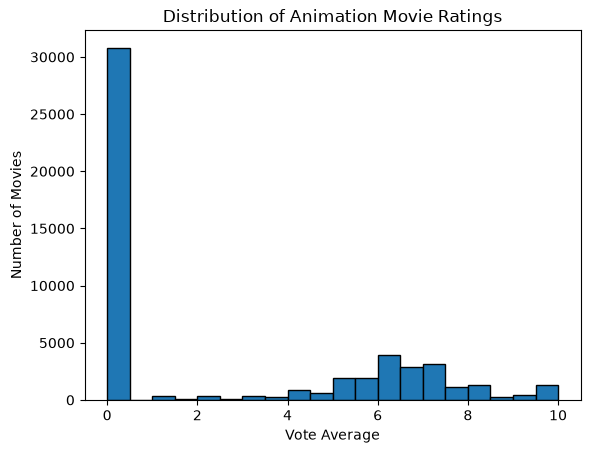

In [90]:
plt.hist(
    df1_animation["vote_average"],
    bins=20,
    edgecolor="black"
)

plt.xlabel("Vote Average")
plt.ylabel("Number of Movies")
plt.title("Distribution of Animation Movie Ratings")
plt.show()

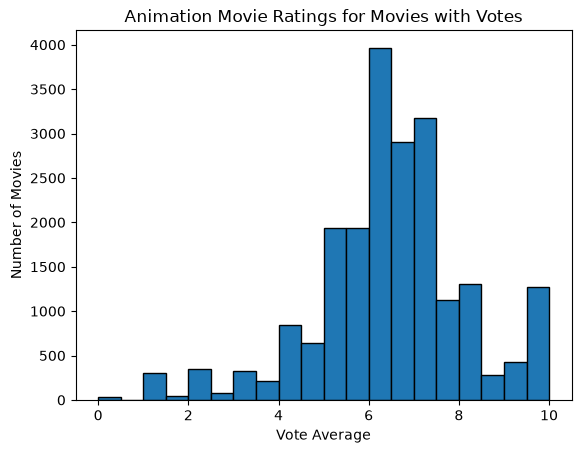

In [91]:
rated_animation = df1_animation[
    df1_animation["vote_count"] > 0
]

plt.hist(
    rated_animation["vote_average"],
    bins=20,
    edgecolor="black"
)

plt.xlabel("Vote Average")
plt.ylabel("Number of Movies")
plt.title("Animation Movie Ratings for Movies with Votes")
plt.show()

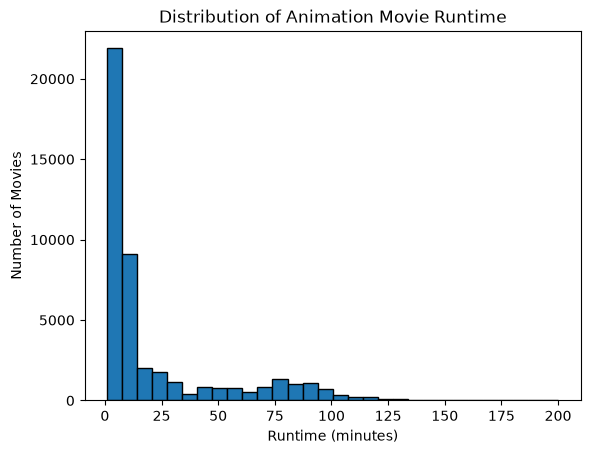

In [92]:
plt.hist(
    df1_animation.loc[df1_animation["runtime"] <= 200, "runtime"].dropna(),
    bins=30,
    edgecolor="black"
)

plt.xlabel("Runtime (minutes)")
plt.ylabel("Number of Movies")
plt.title("Distribution of Animation Movie Runtime")
plt.show()

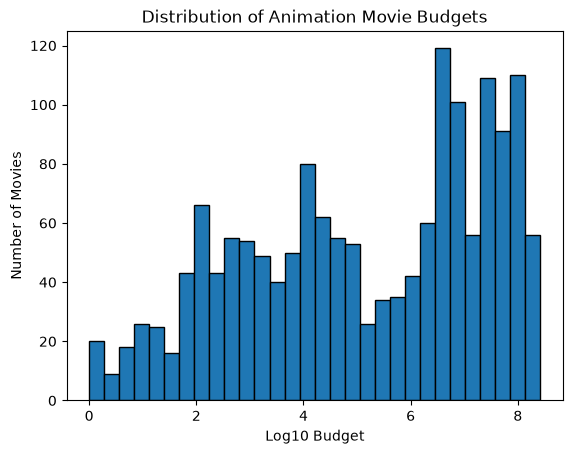

In [93]:
plt.hist(
    np.log10(df1_animation["budget"].dropna()),
    bins=30,
    edgecolor="black"
)

plt.xlabel("Log10 Budget")
plt.ylabel("Number of Movies")
plt.title("Distribution of Animation Movie Budgets")
plt.show()

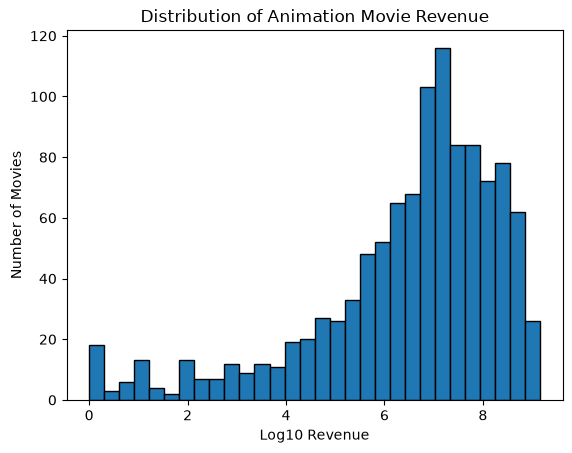

In [94]:
plt.hist(
    np.log10(df1_animation["revenue"].dropna()),
    bins=30,
    edgecolor="black"
)

plt.xlabel("Log10 Revenue")
plt.ylabel("Number of Movies")
plt.title("Distribution of Animation Movie Revenue")
plt.show()

In [ ]:
df1_animation["year"] = df1_animation["release_date"].dt.year

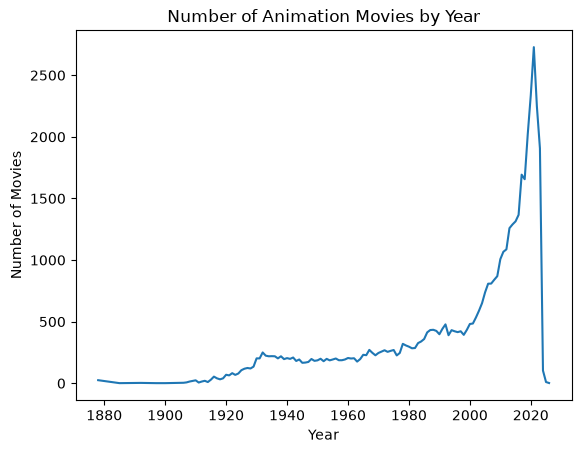

In [96]:
movies_per_year = df1_animation["year"].value_counts().sort_index()

plt.plot(movies_per_year.index, movies_per_year.values)

plt.xlabel("Year")
plt.ylabel("Number of Movies")
plt.title("Number of Animation Movies by Year")
plt.show()

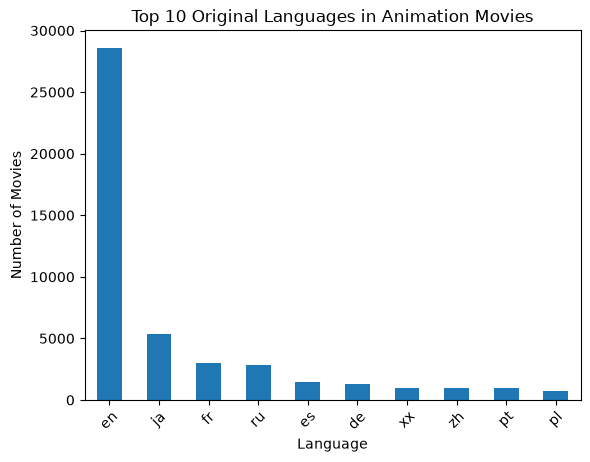

In [97]:
df1_animation["original_language"].value_counts().head(10).plot(
    kind="bar"
)

plt.xlabel("Language")
plt.ylabel("Number of Movies")
plt.title("Top 10 Original Languages in Animation Movies")
plt.xticks(rotation=45)
plt.show()

## Bivariate EDA: Dataframe 1

In [ ]:
financial = df1_animation.dropna(subset=["budget", "revenue"])

financial.shape

(647, 21)

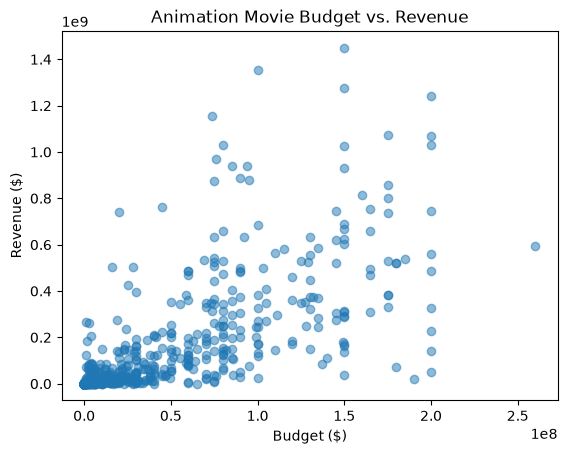

In [99]:
import matplotlib.pyplot as plt

plt.scatter(
    financial["budget"],
    financial["revenue"],
    alpha=0.5
)

plt.xlabel("Budget ($)")
plt.ylabel("Revenue ($)")
plt.title("Animation Movie Budget vs. Revenue")

plt.show()

In [ ]:
financial[["budget", "revenue"]].corr()

,budget,revenue
budget,1.000000,0.715078
revenue,0.715078,1.000000


In [ ]:
financial = df1_animation.dropna(
    subset=["budget", "revenue"]
).copy()

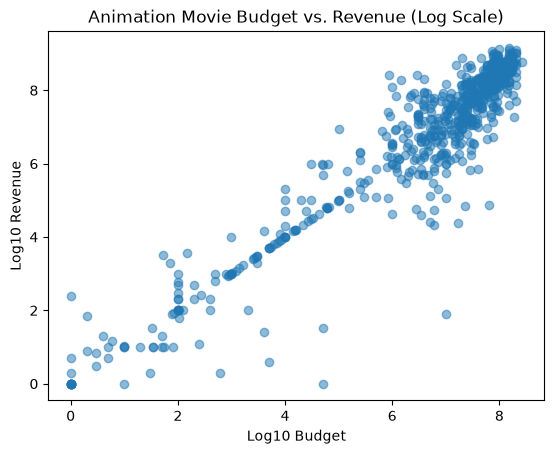

In [102]:
financial["log_budget"] = np.log10(financial["budget"])
financial["log_revenue"] = np.log10(financial["revenue"])

plt.scatter(
    financial["log_budget"],
    financial["log_revenue"],
    alpha=0.5
)

plt.xlabel("Log10 Budget")
plt.ylabel("Log10 Revenue")
plt.title("Animation Movie Budget vs. Revenue (Log Scale)")

plt.show()

In [ ]:
financial[["log_budget", "log_revenue"]].corr()

,log_budget,log_revenue
log_budget,1.000000,0.940802
log_revenue,0.940802,1.000000


In [104]:
ratings = df1_animation[
    df1_animation["vote_count"] > 0
].copy()

ratings.shape

(21166, 21)

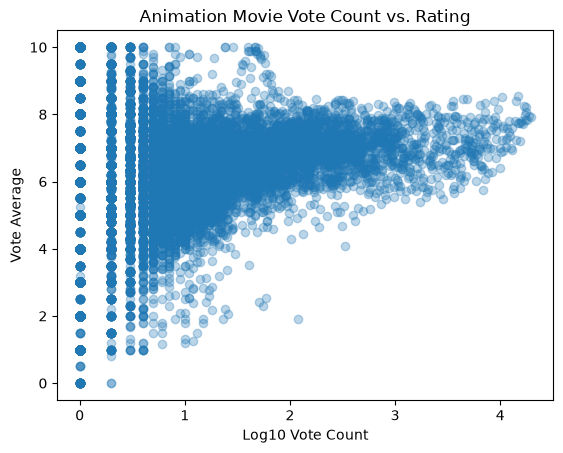

In [105]:
plt.scatter(
    np.log10(ratings["vote_count"]),
    ratings["vote_average"],
    alpha=0.3
)

plt.xlabel("Log10 Vote Count")
plt.ylabel("Vote Average")
plt.title("Animation Movie Vote Count vs. Rating")

plt.show()

In [ ]:
ratings["log_vote_count"] = np.log10(ratings["vote_count"])

ratings[["log_vote_count", "vote_average"]].corr()

,log_vote_count,vote_average
log_vote_count,1.000000,0.088823
vote_average,0.088823,1.000000


In [107]:
pop_revenue = df1_animation.dropna(
    subset=["revenue"]
).copy()

pop_revenue.shape

(1100, 21)

In [ ]:
pop_revenue["log_revenue"] = np.log10(
    pop_revenue["revenue"]
)

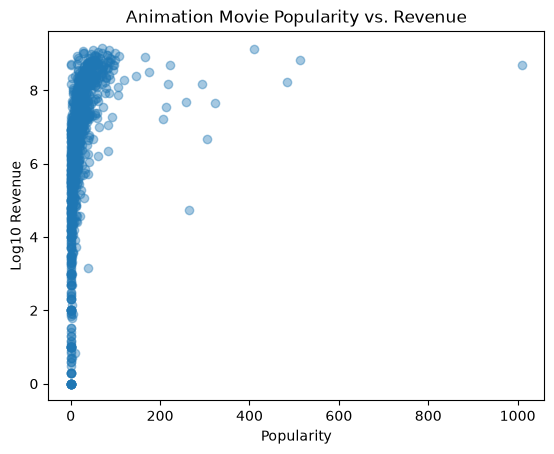

In [109]:
plt.scatter(
    pop_revenue["popularity"],
    pop_revenue["log_revenue"],
    alpha=0.4
)

plt.xlabel("Popularity")
plt.ylabel("Log10 Revenue")
plt.title("Animation Movie Popularity vs. Revenue")

plt.show()

In [ ]:
pop_revenue[
    ["popularity", "log_revenue"]
].corr()

,popularity,log_revenue
popularity,1.000000,0.318253
log_revenue,0.318253,1.000000


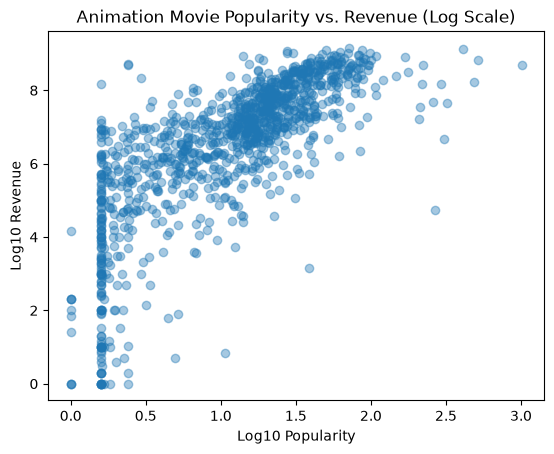

In [111]:
pop_revenue["log_popularity"] = np.log10(
    pop_revenue["popularity"] + 1
)

plt.scatter(
    pop_revenue["log_popularity"],
    pop_revenue["log_revenue"],
    alpha=0.4
)

plt.xlabel("Log10 Popularity")
plt.ylabel("Log10 Revenue")
plt.title("Animation Movie Popularity vs. Revenue (Log Scale)")
plt.show()

In [ ]:
pop_revenue[
    ["log_popularity", "log_revenue"]
].corr()

,log_popularity,log_revenue
log_popularity,1.000000,0.748141
log_revenue,0.748141,1.000000


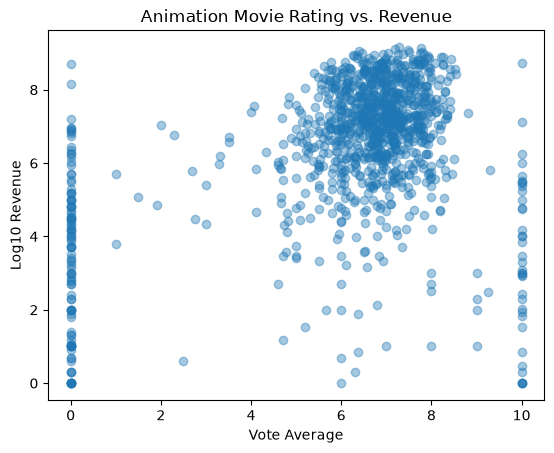

In [113]:
rating_revenue = df1_animation.dropna(
    subset=["revenue"]
).copy()

rating_revenue["log_revenue"] = np.log10(
    rating_revenue["revenue"]
)

plt.scatter(
    rating_revenue["vote_average"],
    rating_revenue["log_revenue"],
    alpha=0.4
)

plt.xlabel("Vote Average")
plt.ylabel("Log10 Revenue")
plt.title("Animation Movie Rating vs. Revenue")
plt.show()

In [114]:
rating_revenue[
    ["vote_average", "log_revenue"]
].corr()

,vote_average,log_revenue
vote_average,1.0000,0.4171
log_revenue,0.4171,1.0000


In [115]:
animation_corr = df1_animation[
    [
        "vote_average",
        "vote_count",
        "runtime",
        "budget",
        "revenue",
        "popularity"
    ]
].corr()

animation_corr

,vote_average,vote_count,runtime,budget,revenue,popularity
vote_average,1.000000,0.115010,0.229633,0.266680,0.166416,0.162871
vote_count,0.115010,1.000000,0.135527,0.692326,0.796104,0.390261
runtime,0.229633,0.135527,1.000000,0.472523,0.240802,0.169641
budget,0.266680,0.692326,0.472523,1.000000,0.715078,0.452804
revenue,0.166416,0.796104,0.240802,0.715078,1.000000,0.385779
popularity,0.162871,0.390261,0.169641,0.452804,0.385779,1.000000


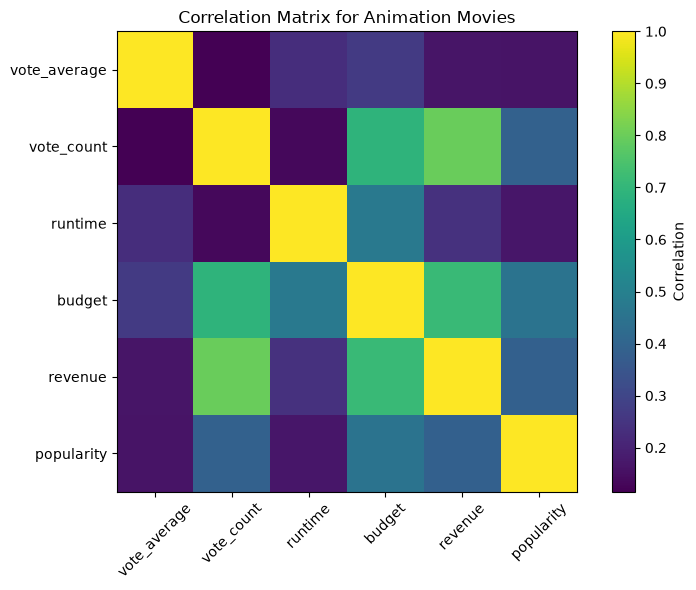

In [116]:
plt.figure(figsize=(8, 6))

plt.imshow(animation_corr)

plt.xticks(
    range(len(animation_corr.columns)),
    animation_corr.columns,
    rotation=45
)

plt.yticks(
    range(len(animation_corr.columns)),
    animation_corr.columns
)

plt.colorbar(label="Correlation")

plt.title("Correlation Matrix for Animation Movies")

plt.tight_layout()
plt.show()

## EDA: Dataframe 2

In [117]:
df2_action = pd.read_csv(
    "data/Action_Movies_clean.csv"
)

In [118]:
df2_action.info()

<class 'pandas.DataFrame'>
RangeIndex: 52452 entries, 0 to 52451
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   movie_id     52452 non-null  str    
 1   movie_name   52451 non-null  str    
 2   year         42284 non-null  float64
 3   runtime      32528 non-null  float64
 4   genre        52452 non-null  str    
 5   rating       29448 non-null  float64
 6   description  52452 non-null  str    
 7   director     47819 non-null  str    
 8   director_id  47819 non-null  str    
 9   star         43212 non-null  str    
 10  star_id      44621 non-null  str    
 11  votes        29450 non-null  float64
 12  gross(in $)  2760 non-null   float64
 13  genre_clean  52452 non-null  str    
dtypes: float64(5), str(9)
memory usage: 5.6 MB


In [126]:
df2_action["year"] = df2_action["year"].astype("Int64")

In [129]:
#df2_action.info()

In [127]:
df2_action[
    ["year", "runtime", "rating", "votes", "gross(in $)"]
].describe()

,year,runtime,rating,votes,gross(in $)
count,42284.0,32528.000000,29448.000000,2.945000e+04,2.760000e+03
mean,1994.060023,100.955392,5.697755,1.159384e+04,4.166888e+07
std,24.140493,30.480450,1.359132,7.039375e+04,8.033689e+07
min,1906.0,1.000000,1.100000,5.000000e+00,7.000000e+00
25%,1979.0,86.000000,4.800000,2.925000e+01,5.459445e+05
50%,1999.0,94.000000,5.800000,1.320000e+02,1.090365e+07
75%,2014.0,112.000000,6.600000,9.440000e+02,4.631759e+07
max,2028.0,999.000000,10.000000,2.675531e+06,9.366622e+08


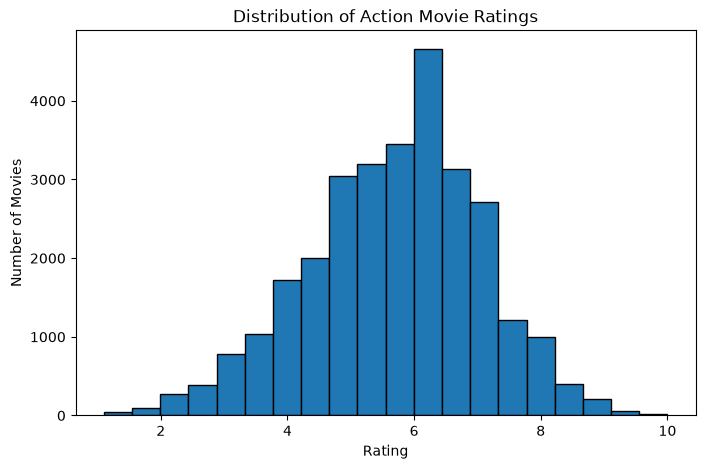

In [121]:
plt.figure(figsize=(8, 5))

plt.hist(
    df2_action["rating"].dropna(),
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Action Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Movies")

plt.show()

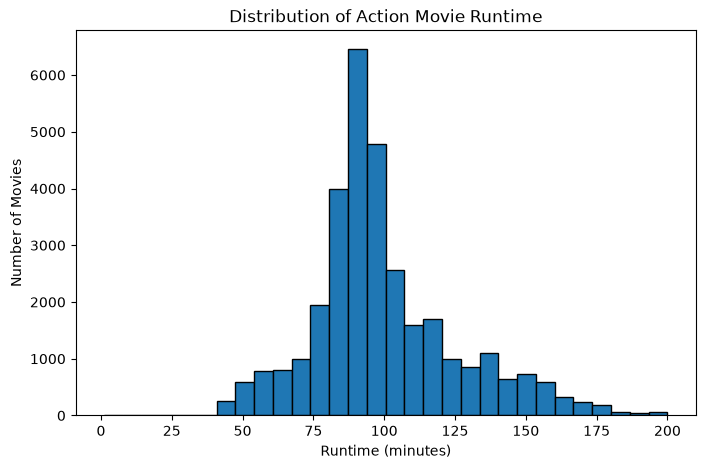

In [122]:
runtime_data = df2_action[
    (df2_action["runtime"].notna()) &
    (df2_action["runtime"] <= 200)
]

plt.figure(figsize=(8, 5))

plt.hist(
    runtime_data["runtime"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Action Movie Runtime")
plt.xlabel("Runtime (minutes)")
plt.ylabel("Number of Movies")

plt.show()

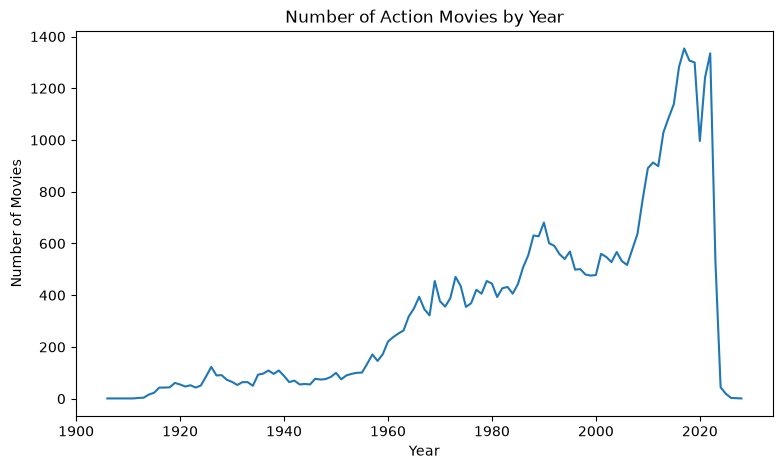

In [123]:
movies_by_year = df2_action["year"].value_counts().sort_index()

plt.figure(figsize=(9, 5))

plt.plot(movies_by_year.index, movies_by_year.values)

plt.title("Number of Action Movies by Year")
plt.xlabel("Year")
plt.ylabel("Number of Movies")

plt.show()

In [130]:
df2_action[df2_action["year"] > 2026][
    ["movie_name", "year", "rating", "votes", "gross(in $)"]
].sort_values("year")

,movie_name,year,rating,votes,gross(in $)
2299,Untitled Adventures of Tintin Sequel,2027,NaN,NaN,NaN
4509,Untitled Star Wars Film,2027,NaN,NaN,NaN
2021,Avatar 5,2028,NaN,NaN,NaN


In [131]:
df2_action[df2_action["year"] > 2026]["year"].value_counts()

year
2027    2
2028    1
Name: count, dtype: Int64

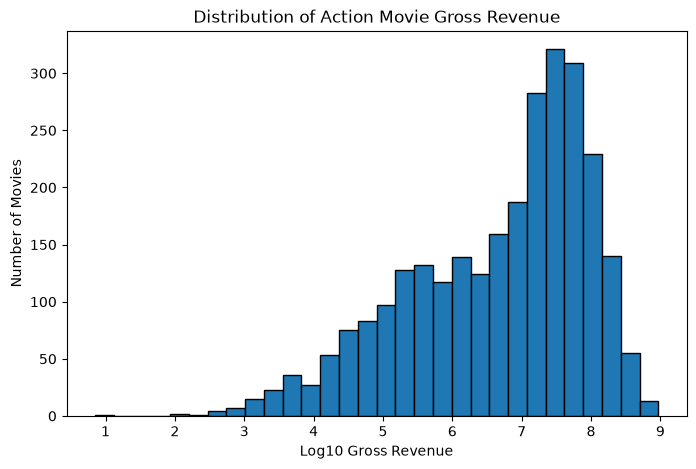

In [132]:
gross_data = df2_action.dropna(subset=["gross(in $)"]).copy()

gross_data["log_gross"] = np.log10(gross_data["gross(in $)"])

plt.figure(figsize=(8, 5))
plt.hist(gross_data["log_gross"], bins=30, edgecolor="black")

plt.xlabel("Log10 Gross Revenue")
plt.ylabel("Number of Movies")
plt.title("Distribution of Action Movie Gross Revenue")

plt.show()

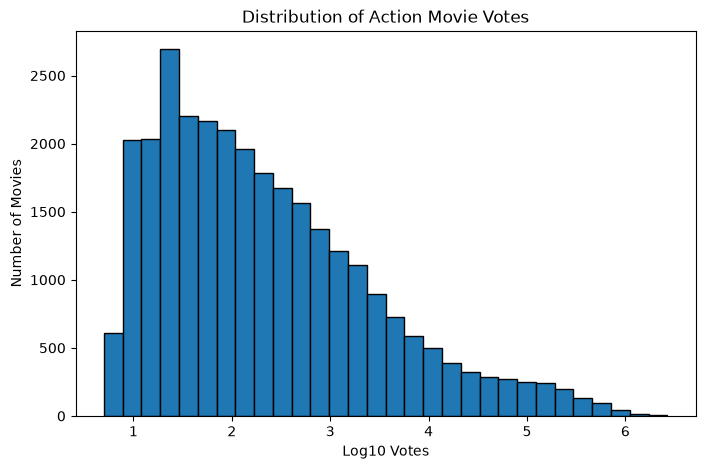

In [133]:
votes_data = df2_action.dropna(subset=["votes"]).copy()

votes_data["log_votes"] = np.log10(votes_data["votes"])

plt.figure(figsize=(8, 5))
plt.hist(votes_data["log_votes"], bins=30, edgecolor="black")

plt.xlabel("Log10 Votes")
plt.ylabel("Number of Movies")
plt.title("Distribution of Action Movie Votes")

plt.show()

### Bivariate EDA: Dataframe 2

In [135]:
action_ratings = df2_action.dropna(
    subset=["votes", "rating"]
).copy()

action_ratings.shape

(29448, 14)

In [136]:
action_ratings["log_votes"] = np.log10(
    action_ratings["votes"]
)

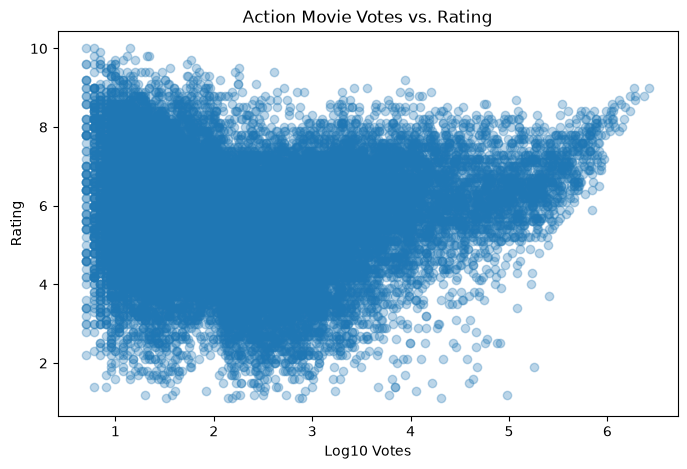

In [137]:
plt.figure(figsize=(8, 5))

plt.scatter(
    action_ratings["log_votes"],
    action_ratings["rating"],
    alpha=0.3
)

plt.xlabel("Log10 Votes")
plt.ylabel("Rating")
plt.title("Action Movie Votes vs. Rating")

plt.show()

In [138]:
action_ratings[
    ["log_votes", "rating"]
].corr()

,log_votes,rating
log_votes,1.000000,0.036617
rating,0.036617,1.000000


In [139]:
rating_gross = df2_action.dropna(
    subset=["rating", "gross(in $)"]
).copy()

rating_gross.shape

(2760, 14)

In [140]:
rating_gross["log_gross"] = np.log10(
    rating_gross["gross(in $)"]
)

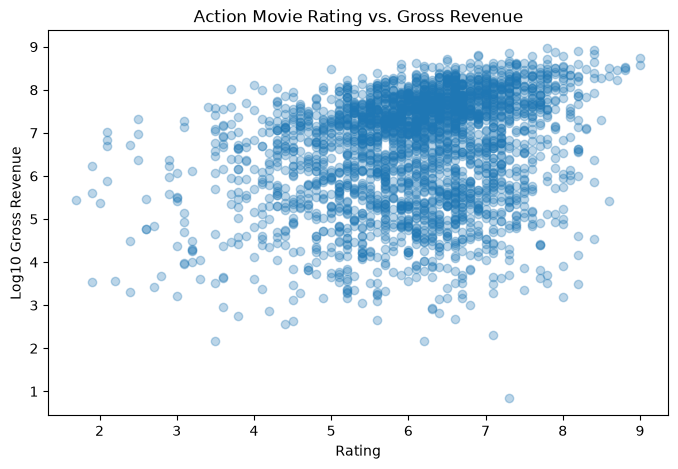

In [141]:
plt.figure(figsize=(8, 5))

plt.scatter(
    rating_gross["rating"],
    rating_gross["log_gross"],
    alpha=0.3
)

plt.xlabel("Rating")
plt.ylabel("Log10 Gross Revenue")
plt.title("Action Movie Rating vs. Gross Revenue")

plt.show()

In [142]:
rating_gross[
    ["rating", "log_gross"]
].corr()

,rating,log_gross
rating,1.00000,0.27101
log_gross,0.27101,1.00000


In [146]:
votes_gross = df2_action.dropna(
    subset=["votes", "gross(in $)"]
).copy()

votes_gross["log_votes"] = np.log10(
    votes_gross["votes"]
)

votes_gross["log_gross"] = np.log10(
    votes_gross["gross(in $)"]
)

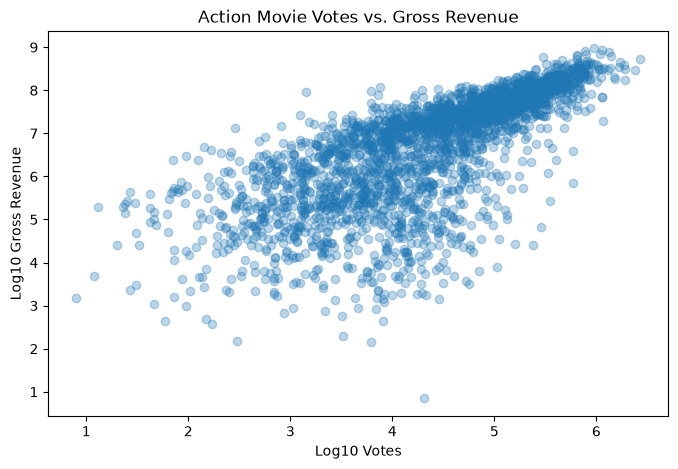

In [144]:
plt.figure(figsize=(8, 5))

plt.scatter(
    votes_gross["log_votes"],
    votes_gross["log_gross"],
    alpha=0.3
)

plt.xlabel("Log10 Votes")
plt.ylabel("Log10 Gross Revenue")
plt.title("Action Movie Votes vs. Gross Revenue")

plt.show()

In [145]:
votes_gross[
    ["log_votes", "log_gross"]
].corr()

,log_votes,log_gross
log_votes,1.000000,0.720485
log_gross,0.720485,1.000000


## EDA: Dataset 3

In [147]:
df3_nvda = pd.read_csv("data/NVDA_clean.csv")

In [148]:
df3_nvda.info()

<class 'pandas.DataFrame'>
RangeIndex: 6116 entries, 0 to 6115
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       6116 non-null   str    
 1   Open       6116 non-null   float64
 2   High       6116 non-null   float64
 3   Low        6116 non-null   float64
 4   Close      6116 non-null   float64
 5   Adj Close  6116 non-null   float64
 6   Volume     6116 non-null   int64  
dtypes: float64(5), int64(1), str(1)
memory usage: 334.6 KB


In [149]:
df3_nvda.describe()

,Open,High,Low,Close,Adj Close,Volume
count,6116.000000,6116.000000,6116.000000,6116.000000,6116.000000,6.116000e+03
mean,53.052266,54.017201,52.031700,53.064741,52.794253,6.221933e+07
std,121.267334,123.423982,118.835114,121.183234,121.214864,4.316714e+07
min,0.608333,0.656667,0.600000,0.614167,0.563377,4.564400e+06
25%,2.959688,3.027500,2.875000,2.950391,2.707880,3.615840e+07
50%,4.683750,4.747500,4.608750,4.682500,4.389289,5.206235e+07
75%,42.101873,42.645625,41.500000,42.102499,41.741090,7.465490e+07
max,958.510010,974.000000,935.099976,950.020020,950.020020,9.230856e+08


In [150]:
df3_nvda["Date"] = pd.to_datetime(df3_nvda["Date"])

df3_nvda = df3_nvda.sort_values("Date")

df3_nvda.info()

<class 'pandas.DataFrame'>
RangeIndex: 6116 entries, 0 to 6115
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       6116 non-null   datetime64[us]
 1   Open       6116 non-null   float64       
 2   High       6116 non-null   float64       
 3   Low        6116 non-null   float64       
 4   Close      6116 non-null   float64       
 5   Adj Close  6116 non-null   float64       
 6   Volume     6116 non-null   int64         
dtypes: datetime64[us](1), float64(5), int64(1)
memory usage: 334.6 KB


In [151]:
df3_nvda["Date"].min(), df3_nvda["Date"].max()

(Timestamp('2000-01-03 00:00:00'), Timestamp('2024-04-24 00:00:00'))

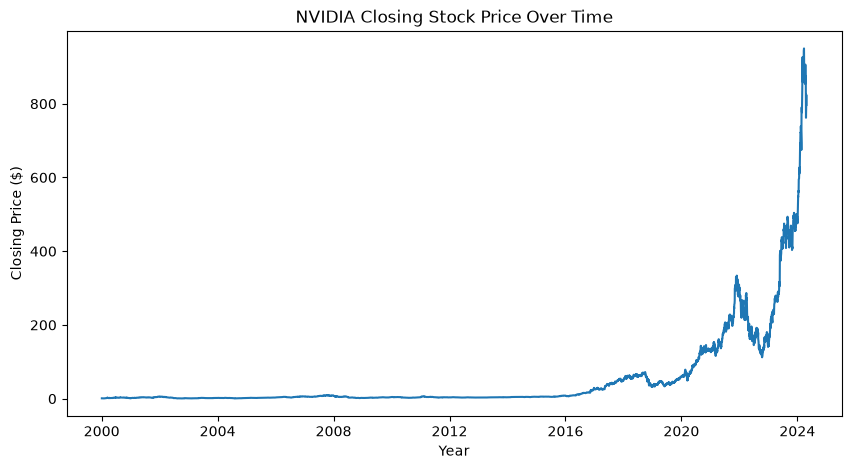

In [152]:
plt.figure(figsize=(10, 5))

plt.plot(
    df3_nvda["Date"],
    df3_nvda["Close"]
)

plt.xlabel("Year")
plt.ylabel("Closing Price ($)")
plt.title("NVIDIA Closing Stock Price Over Time")

plt.show()

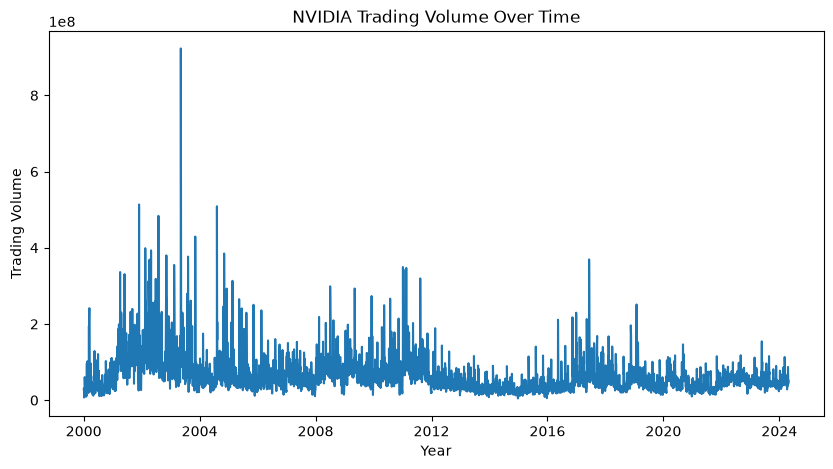

In [153]:
plt.figure(figsize=(10, 5))

plt.plot(
    df3_nvda["Date"],
    df3_nvda["Volume"]
)

plt.xlabel("Year")
plt.ylabel("Trading Volume")
plt.title("NVIDIA Trading Volume Over Time")

plt.show()

In [154]:
df3_nvda["daily_return"] = df3_nvda["Close"].pct_change() * 100

df3_nvda["daily_return"].describe()

count    6115.000000
mean        0.179694
std         3.753493
min       -35.233526
25%        -1.585345
50%         0.127389
75%         1.787422
max        42.414523
Name: daily_return, dtype: float64

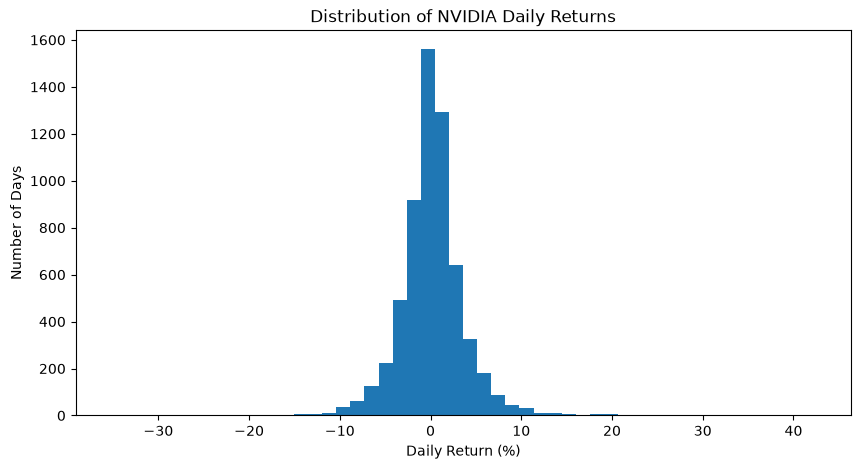

In [155]:
plt.figure(figsize=(10, 5))

plt.hist(
    df3_nvda["daily_return"].dropna(),
    bins=50
)

plt.xlabel("Daily Return (%)")
plt.ylabel("Number of Days")
plt.title("Distribution of NVIDIA Daily Returns")

plt.show()

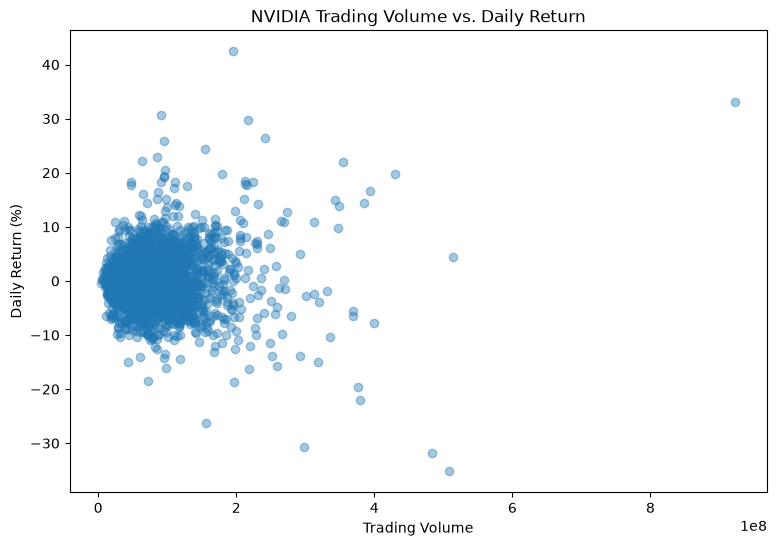

In [156]:
volume_return = df3_nvda.dropna(
    subset=["Volume", "daily_return"]
).copy()

plt.figure(figsize=(9, 6))

plt.scatter(
    volume_return["Volume"],
    volume_return["daily_return"],
    alpha=0.4
)

plt.xlabel("Trading Volume")
plt.ylabel("Daily Return (%)")
plt.title("NVIDIA Trading Volume vs. Daily Return")

plt.show()

In [157]:
volume_return[
    ["Volume", "daily_return"]
].corr()

,Volume,daily_return
Volume,1.000000,0.049699
daily_return,0.049699,1.000000


In [158]:
df3_nvda["absolute_return"] = df3_nvda["daily_return"].abs()

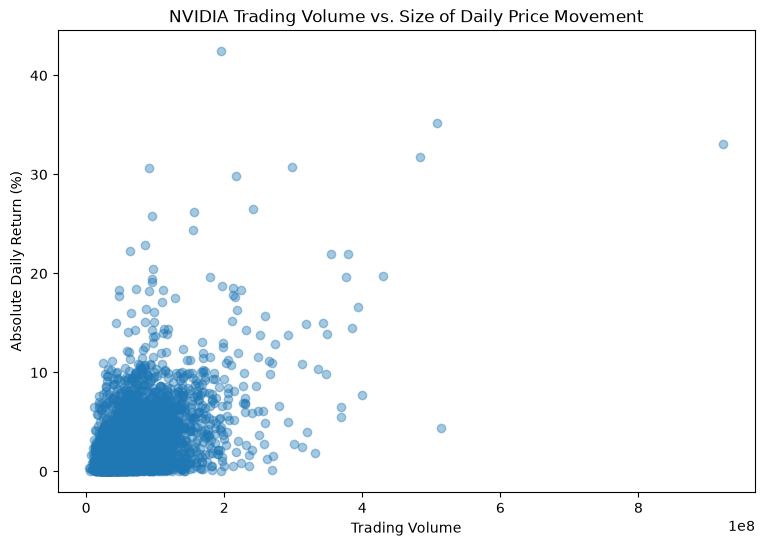

In [159]:
volume_abs_return = df3_nvda.dropna(
    subset=["Volume", "absolute_return"]
).copy()

plt.figure(figsize=(9, 6))

plt.scatter(
    volume_abs_return["Volume"],
    volume_abs_return["absolute_return"],
    alpha=0.4
)

plt.xlabel("Trading Volume")
plt.ylabel("Absolute Daily Return (%)")
plt.title("NVIDIA Trading Volume vs. Size of Daily Price Movement")

plt.show()

In [160]:
volume_abs_return[
    ["Volume", "absolute_return"]
].corr()

,Volume,absolute_return
Volume,1.000000,0.514037
absolute_return,0.514037,1.000000


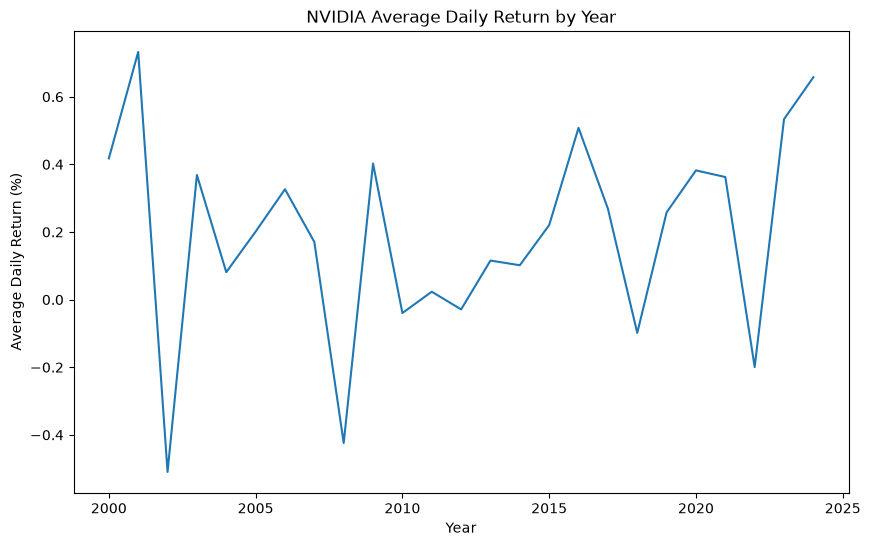

In [161]:
df3_nvda["year"] = df3_nvda["Date"].dt.year

annual_return = (
    df3_nvda.groupby("year")["daily_return"]
    .mean()
)

plt.figure(figsize=(10, 6))

plt.plot(
    annual_return.index,
    annual_return.values
)

plt.xlabel("Year")
plt.ylabel("Average Daily Return (%)")
plt.title("NVIDIA Average Daily Return by Year")

plt.show()